# 人民生活 · 逐表数据可视化分析

基于国家统计局「数据库 — 季度数据」（2025Q2 — 2026Q3，共 6 个季度）对**人民生活**主题的
7 张数据表逐一进行可视化分析。

| # | 数据表 | 分析内容 |
| --- | --- | --- |
| 1 | 全国居民人均收入情况 | 收入与中位数对比、四项收入构成 |
| 2 | 全国居民人均支出情况 | 八大类消费结构、恩格尔系数环形图 |
| 3 | 城镇居民人均收入情况 | 城乡收入对比、四项收入构成（横向条形） |
| 4 | 城镇居民人均支出情况 | 城乡八大类对比、消费支出走势 |
| 5 | 农村居民人均收入情况 | 农村收入走势、四项收入占比环形图 |
| 6 | 农村居民人均支出情况 | 八大类堆积、城乡支出雷达图 |
| 7 | 外出务工情况 | 务工劳动力人数与月均收入双轴图 |


**口径说明**：收入与消费支出均为**累计值**口径（人均），"累计增长"为统计局发布的实际/名义增速
（人均可支配收入增速为扣除价格因素的实际增速）；外出务工数据为**单季度**数据（2025Q4 未发布）。

In [1]:
# 0 环境与工具函数
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# 中文字体：西文/数字 Times New Roman，中文回退黑体（matplotlib ≥3.6 逐字符回退）
plt.rcParams['font.family'] = ['Times New Roman', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.titlesize'] = 12.5
plt.rcParams['axes.titleweight'] = 'bold'

DATA_DIR = next(c for c in [Path('data'), Path('人民生活/data'), Path('.')]
                if (c / '全国居民人均收入情况.csv').exists())

QMAP = {'一': 1, '二': 2, '三': 3, '四': 4}
PAL = ['#0071e3', '#34c759', '#ff9f0a', '#ff375f', '#bf5af2', '#64d2ff', '#ffd60a', '#8e8e93']

# 八大类消费支出 / 四项收入（指标名前缀共用部分）
EXP_CATS = ['食品烟酒', '衣着', '居住', '生活用品及服务', '交通通信', '教育文化娱乐', '医疗保健', '其他用品及服务']
INC_CATS = ['工资性', '经营净', '财产净', '转移净']


def load_table(fname):
    """解析国家统计局季度 CSV（制表符分隔），返回 (季度列表[时间正序], {指标名: 数值列表})。"""
    text = (DATA_DIR / fname).read_text(encoding='utf-8-sig')
    quarters, rows = None, {}
    for line in text.splitlines():
        if '\t' not in line:
            continue
        cells = [c.replace(',', '').strip() for c in line.split('\t')]
        first = re.sub(r'\s+', '', cells[0] or '')
        if first == '指标':
            quarters = []
            for c in cells[1:]:
                if not c:
                    continue
                m = re.match(r'(\d{4})年第([一二三四])季度', c)
                if m:
                    quarters.append(f'{m.group(1)}Q{QMAP[m.group(2)]}')
            continue
        if not first or first.startswith(('注', '数据库', '时间', '数据来源')):
            continue
        vals = []
        for c in cells[1:]:
            try:
                vals.append(float(c))
            except ValueError:
                vals.append(None)
        while vals and vals[-1] is None:
            vals.pop()
        rows[first] = vals
    quarters = list(reversed(quarters))            # 表头逆序 → 时间正序
    rows = {k: list(reversed(v)) for k, v in rows.items()}
    return quarters, rows


def col(rows, prefix):
    """按指标名前缀取一列数值。"""
    key = next((k for k in rows if k.startswith(prefix)), None)
    if key is None:
        raise KeyError(f'未找到指标：{prefix}')
    return rows[key]


def short_q(q):
    """'2025Q2' → '25Q2'（坐标轴短标签）。"""
    return q[2:]


print('数据目录：', DATA_DIR.resolve())
print('工具函数加载完成，可逐格运行下方分析。')

数据目录： C:\Users\21409\Desktop\商业数据分析+数据可视化\数据可视化\国家统计局数据可视化分析\人民生活\data
工具函数加载完成，可逐格运行下方分析。


## 表 1 · 全国居民人均收入情况

**图 1** 分组柱状图 + 折线：人均可支配收入 vs 中位数（累计值）与累计增长；
**图 2** 堆积柱状图：四项收入构成（工资性 / 经营净 / 财产净 / 转移净）。

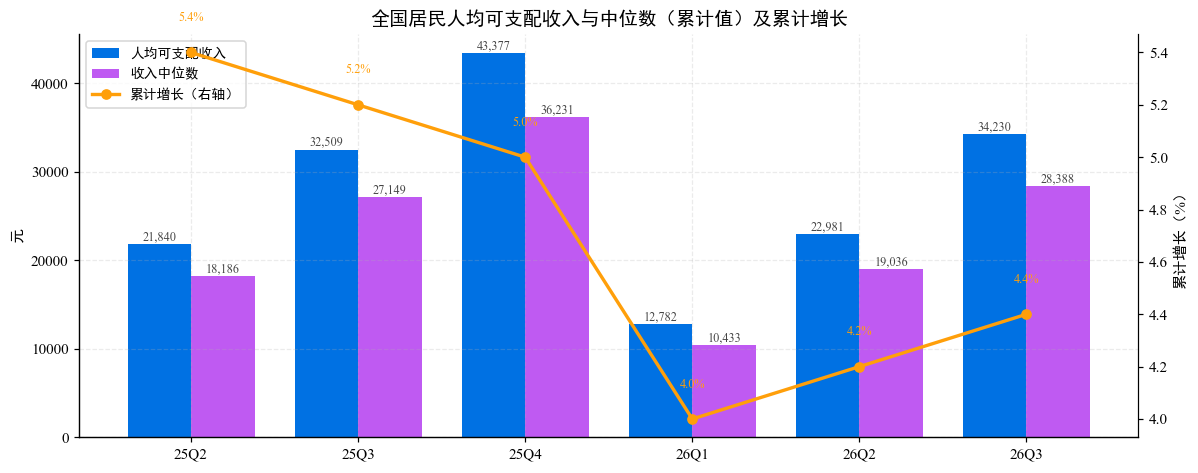

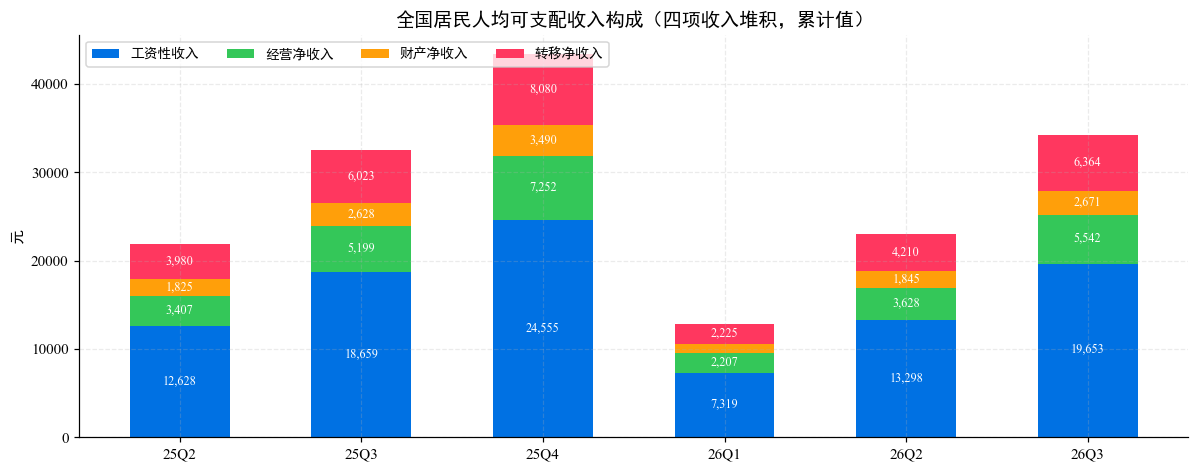

In [2]:
# 表 1：全国居民人均收入情况
quarters, rows = load_table('全国居民人均收入情况.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

income = col(rows, '居民人均可支配收入累计值')
income_g = col(rows, '居民人均可支配收入累计增长')
median = col(rows, '居民人均可支配收入中位数累计值')

# 图 1：分组柱状图（收入 vs 中位数）+ 累计增长折线（右轴）
fig, ax = plt.subplots(figsize=(11, 4.4))
w = 0.38
b1 = ax.bar(x - w / 2, income, w, label='人均可支配收入', color=PAL[0])
b2 = ax.bar(x + w / 2, median, w, label='收入中位数', color=PAL[4])
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 350,
            f'{b.get_height():,.0f}', ha='center', fontsize=8, color='#444444')
ax2 = ax.twinx()
ax2.plot(x, income_g, 'o-', color=PAL[2], lw=2.2, label='累计增长（右轴）')
for xi, yi in zip(x, income_g):
    ax2.text(xi, yi + 0.12, f'{yi:.1f}%', ha='center', fontsize=8, color=PAL[2])
ax2.set_ylabel('累计增长（%）')
ax2.spines['right'].set_visible(True)
ax2.grid(False)
ax.set_xticks(x, labels)
ax.set_ylabel('元')
ax.set_title('全国居民人均可支配收入与中位数（累计值）及累计增长')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：四项收入构成堆积柱状图
comp = np.array([col(rows, f'居民人均可支配{c}收入累计值') for c in INC_CATS])
fig, ax = plt.subplots(figsize=(11, 4.4))
bottom = np.zeros(len(quarters))
for i, (c, vals) in enumerate(zip(INC_CATS, comp)):
    ax.bar(x, vals, 0.55, bottom=bottom, label=f'{c}收入', color=PAL[i])
    for xi, v in enumerate(vals):
        if v > 1500:
            ax.text(xi, bottom[xi] + v / 2, f'{v:,.0f}', ha='center', va='center', fontsize=8, color='white')
    bottom += vals
ax.set_xticks(x, labels)
ax.set_ylabel('元')
ax.set_title('全国居民人均可支配收入构成（四项收入堆积，累计值）')
ax.legend(ncol=4, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

## 表 2 · 全国居民人均支出情况

**图 1** 堆积柱状图：八大类消费支出结构（累计值）；
**图 2** 环形图：最新季度八大类支出占比，中心标注**恩格尔系数**（食品烟酒支出占消费支出比重）。

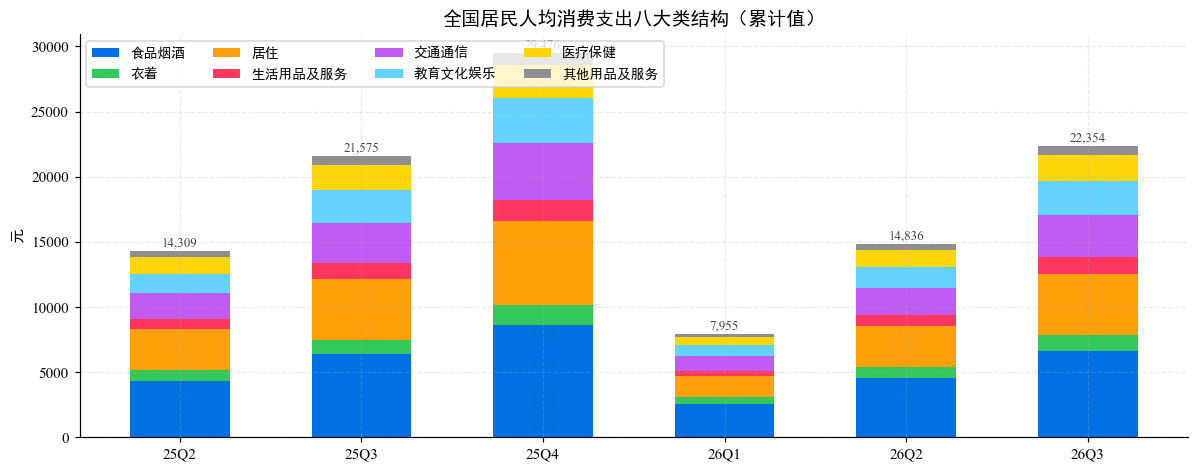

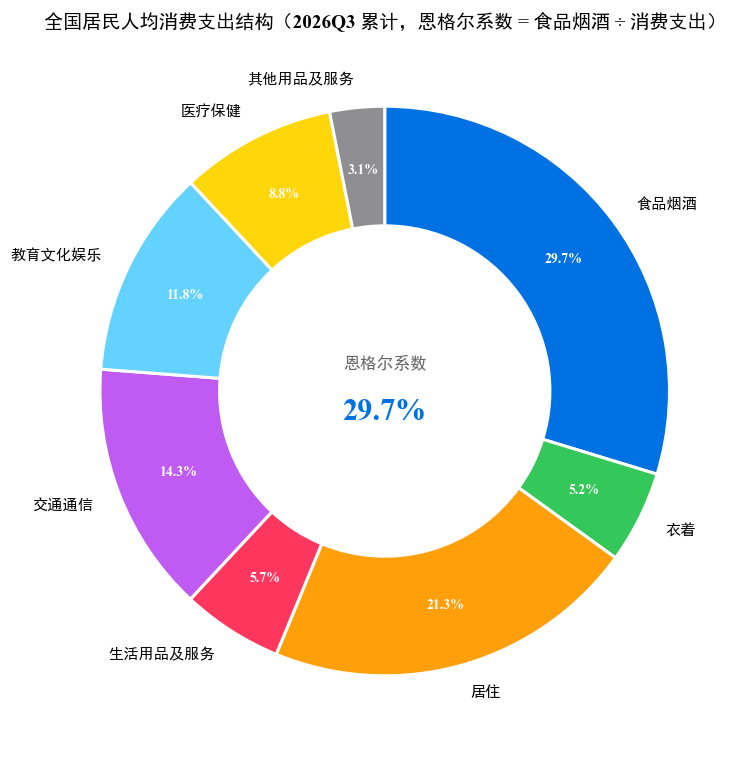

In [3]:
# 表 2：全国居民人均支出情况
quarters, rows = load_table('全国居民人均支出情况.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

exp_total = col(rows, '居民人均消费支出累计值')
cats_val = np.array([col(rows, f'居民人均{c}支出累计值') for c in EXP_CATS])

# 图 1：八大类消费支出堆积柱状图
fig, ax = plt.subplots(figsize=(11, 4.4))
bottom = np.zeros(len(quarters))
for i, (c, vals) in enumerate(zip(EXP_CATS, cats_val)):
    ax.bar(x, vals, 0.55, bottom=bottom, label=c, color=PAL[i])
    bottom += vals
for xi, tv in enumerate(exp_total):
    ax.text(xi, bottom[xi] + 300, f'{tv:,.0f}', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels)
ax.set_ylabel('元')
ax.set_title('全国居民人均消费支出八大类结构（累计值）')
ax.legend(ncol=4, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：最新季度八大类支出占比环形图（中心为恩格尔系数）
latest = len(quarters) - 1
engel = cats_val[0][latest] / exp_total[latest] * 100
fig, ax = plt.subplots(figsize=(7.6, 7.0))
wedges, texts, autotexts = ax.pie(
    cats_val[:, latest], labels=EXP_CATS, autopct='%1.1f%%', startangle=90,
    counterclock=False, colors=PAL, pctdistance=0.78,
    wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 10})
for t in autotexts:
    t.set_color('white'); t.set_fontweight('bold'); t.set_fontsize(9)
ax.text(0, 0.08, '恩格尔系数', ha='center', fontsize=11, color='#666666')
ax.text(0, -0.10, f'{engel:.1f}%', ha='center', fontsize=20, fontweight='bold', color=PAL[0])
ax.set_title(f'全国居民人均消费支出结构（{quarters[latest]} 累计，恩格尔系数 = 食品烟酒 ÷ 消费支出）')
plt.tight_layout()
plt.show()

## 表 3 · 城镇居民人均收入情况

**图 1** 折线图：城镇 / 全国 / 农村 三口径人均可支配收入对比，右轴为**城乡收入比**（城镇 ÷ 农村）；
**图 2** 横向条形图：城镇四项收入构成（最新季度，含累计增长标注）。

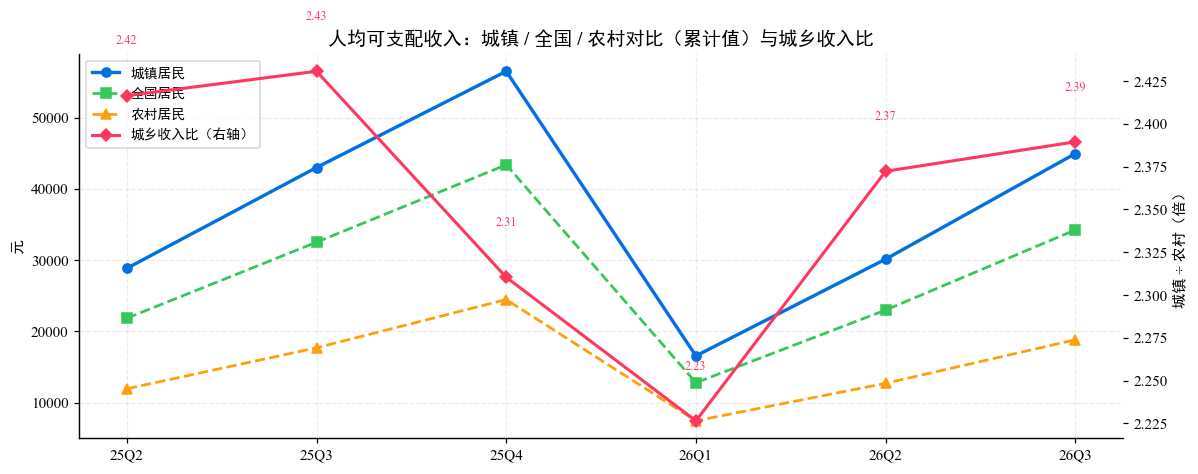

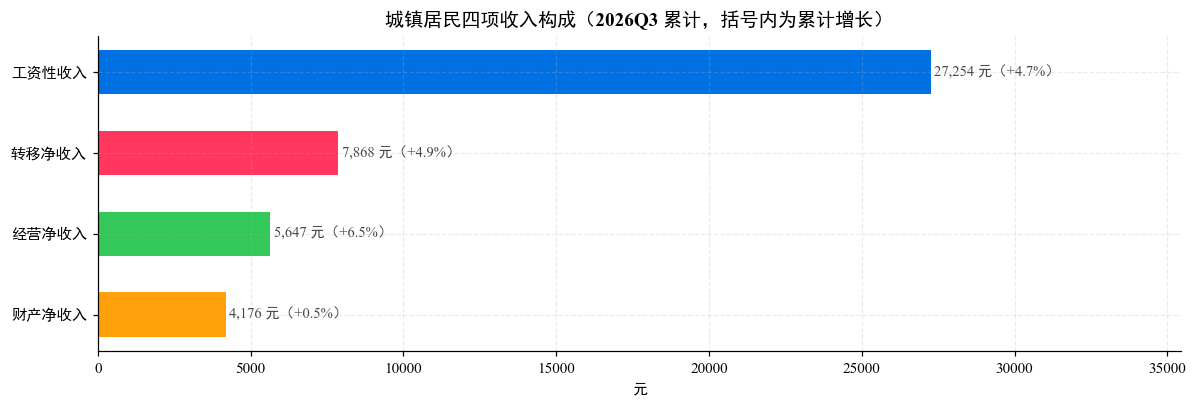

In [4]:
# 表 3：城镇居民人均收入情况（与全国 / 农村对比）
q_u, rows_u = load_table('城镇居民人均收入情况.csv')
q_n, rows_n = load_table('全国居民人均收入情况.csv')
q_r, rows_r = load_table('农村居民人均收入情况.csv')
assert q_u == q_n == q_r, '三张表的季度轴不一致'
x = np.arange(len(q_u))
labels = [short_q(q) for q in q_u]

urban = col(rows_u, '城镇居民人均可支配收入累计值')
national = col(rows_n, '居民人均可支配收入累计值')
rural = col(rows_r, '农村居民人均可支配收入累计值')
ratio = [u / r for u, r in zip(urban, rural)]

# 图 1：三口径收入折线 + 城乡收入比（右轴）
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(x, urban, 'o-', color=PAL[0], lw=2.2, label='城镇居民')
ax.plot(x, national, 's--', color=PAL[1], lw=1.8, label='全国居民')
ax.plot(x, rural, '^--', color=PAL[2], lw=1.8, label='农村居民')
ax2 = ax.twinx()
ax2.plot(x, ratio, 'D-', color=PAL[3], lw=2, label='城乡收入比（右轴）')
for xi, yi in zip(x, ratio):
    ax2.text(xi, yi + 0.03, f'{yi:.2f}', ha='center', fontsize=8, color=PAL[3])
ax2.set_ylabel('城镇 ÷ 农村（倍）')
ax2.grid(False)
ax.set_xticks(x, labels)
ax.set_ylabel('元')
ax.set_title('人均可支配收入：城镇 / 全国 / 农村对比（累计值）与城乡收入比')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：城镇四项收入构成横向条形图（最新季度，含累计增长）
latest = len(q_u) - 1
comp_v = [col(rows_u, f'城镇居民人均可支配{c}收入累计值')[latest] for c in INC_CATS]
comp_g = [col(rows_u, f'城镇居民人均可支配{c}收入累计增长')[latest] for c in INC_CATS]
order = np.argsort(comp_v)
fig, ax = plt.subplots(figsize=(11, 3.8))
bars = ax.barh([f'{INC_CATS[i]}收入' for i in order], [comp_v[i] for i in order],
               0.55, color=[PAL[i] for i in order])
for b, gi in zip(bars, [comp_g[i] for i in order]):
    ax.text(b.get_width() + 120, b.get_y() + b.get_height() / 2,
            f'{b.get_width():,.0f} 元（{gi:+.1f}%）', va='center', fontsize=9.5, color='#444444')
ax.set_xlim(0, max(comp_v) * 1.3)
ax.set_xlabel('元')
ax.set_title(f'城镇居民四项收入构成（{q_u[latest]} 累计，括号内为累计增长）')
plt.tight_layout()
plt.show()

## 表 4 · 城镇居民人均支出情况

**图 1** 分组横向条形图：城镇 vs 全国八大类支出对比（最新季度）；
**图 2** 组合图：城镇消费支出累计柱 + 累计增长折线（右轴）。

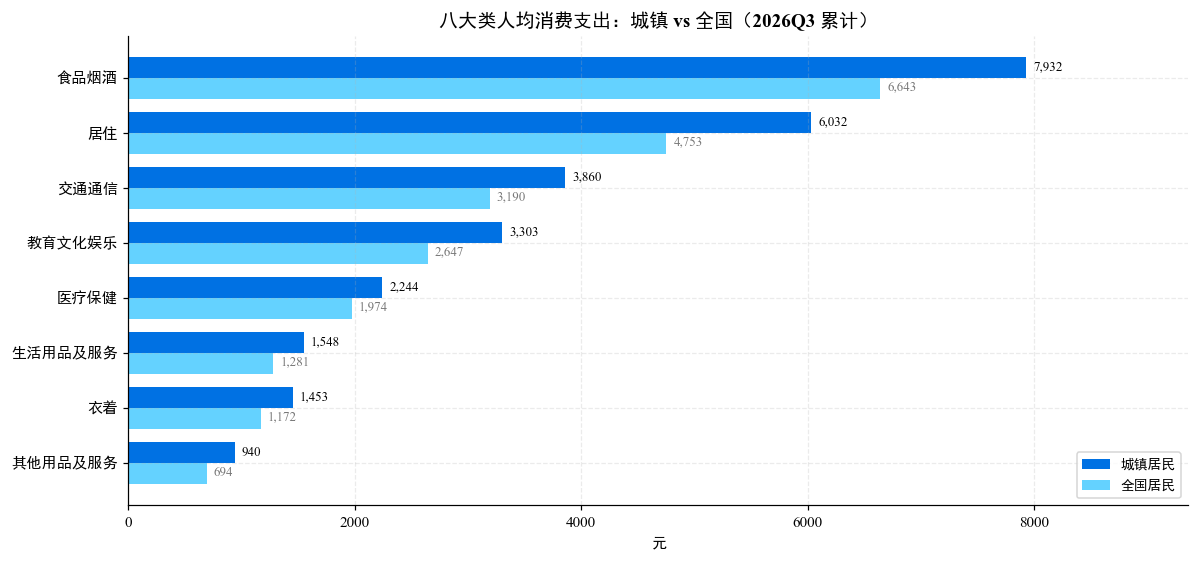

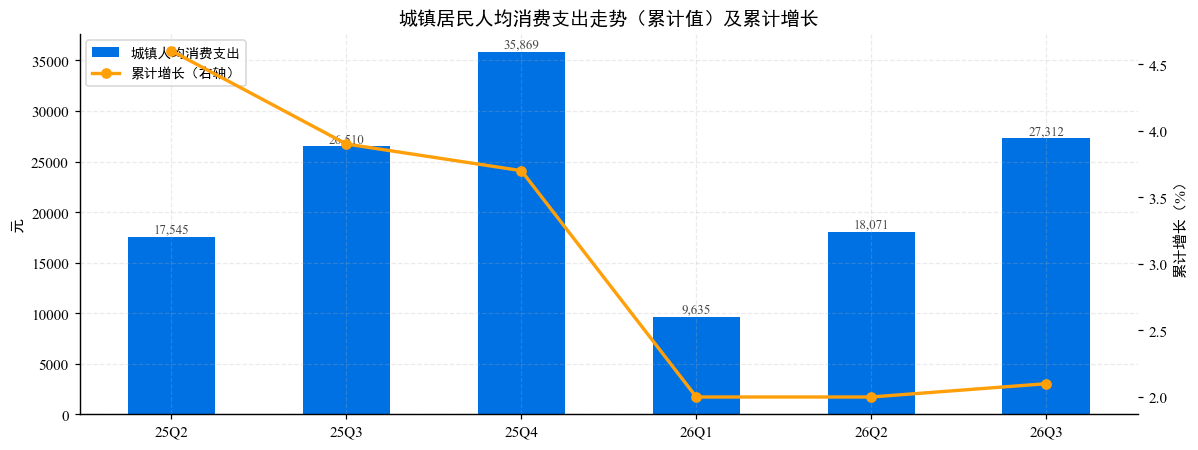

In [5]:
# 表 4：城镇居民人均支出情况（与全国对比）
q_c, rows_c = load_table('城镇居民人均支出情况.csv')
q_n, rows_n = load_table('全国居民人均支出情况.csv')
x = np.arange(len(EXP_CATS))

urban_cats = [col(rows_c, f'城镇居民人均{c}支出累计值')[-1] for c in EXP_CATS]
nat_cats = [col(rows_n, f'居民人均{c}支出累计值')[-1] for c in EXP_CATS]
order = np.argsort(urban_cats)

# 图 1：城镇 vs 全国 八大类支出分组横向条形（最新季度）
fig, ax = plt.subplots(figsize=(11, 5.2))
h = 0.38
ax.barh(x + h / 2, [urban_cats[i] for i in order], h, label='城镇居民', color=PAL[0])
ax.barh(x - h / 2, [nat_cats[i] for i in order], h, label='全国居民', color=PAL[5])
ax.set_yticks(x, [EXP_CATS[i] for i in order])
for i, xi in enumerate(order):
    ax.text(urban_cats[xi] + 60, i + h / 2, f'{urban_cats[xi]:,.0f}', va='center', fontsize=8.5)
    ax.text(nat_cats[xi] + 60, i - h / 2, f'{nat_cats[xi]:,.0f}', va='center', fontsize=8.5, color='#777777')
ax.set_xlim(0, max(urban_cats) * 1.18)
ax.set_xlabel('元')
ax.set_title(f'八大类人均消费支出：城镇 vs 全国（{q_c[-1]} 累计）')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：城镇消费支出累计柱 + 累计增长折线（右轴）
exp_c = col(rows_c, '城镇居民人均消费支出累计值')
exp_g = col(rows_c, '城镇居民人均消费支出累计增长')
labels = [short_q(q) for q in q_c]
xq = np.arange(len(q_c))
fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.bar(xq, exp_c, 0.5, label='城镇人均消费支出', color=PAL[0])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 350,
            f'{b.get_height():,.0f}', ha='center', fontsize=8.5, color='#444444')
ax2 = ax.twinx()
ax2.plot(xq, exp_g, 'o-', color=PAL[2], lw=2.2, label='累计增长（右轴）')
ax2.set_ylabel('累计增长（%）')
ax2.grid(False)
ax.set_xticks(xq, labels)
ax.set_ylabel('元')
ax.set_title('城镇居民人均消费支出走势（累计值）及累计增长')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

## 表 5 · 农村居民人均收入情况

**图 1** 组合图：农村人均可支配收入柱 + 累计增长折线（右轴）；
**图 2** 环形图：农村四项收入构成（最新季度）。

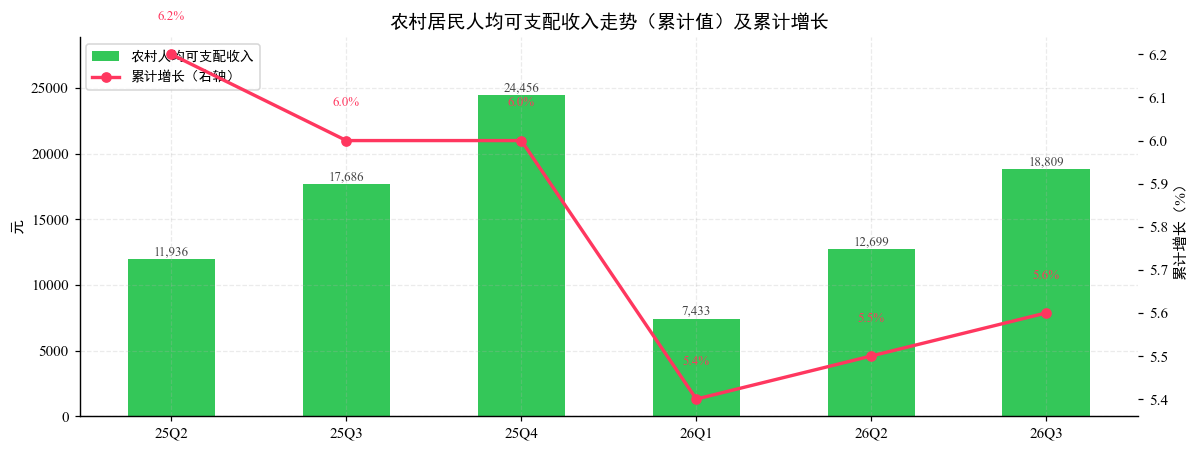

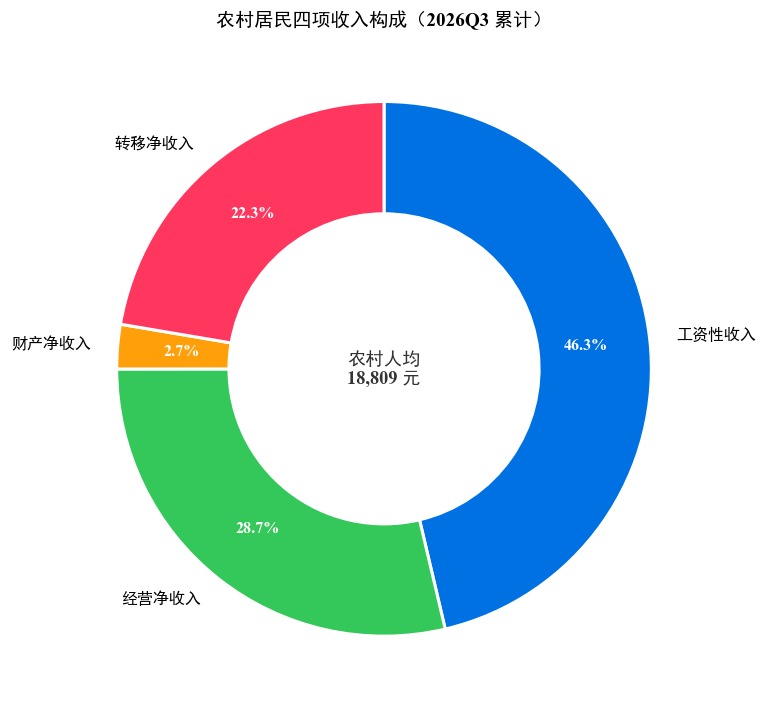

In [6]:
# 表 5：农村居民人均收入情况
quarters, rows = load_table('农村居民人均收入情况.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

rural = col(rows, '农村居民人均可支配收入累计值')
rural_g = col(rows, '农村居民人均可支配收入累计增长')

# 图 1：农村收入柱 + 累计增长线（右轴）
fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.bar(x, rural, 0.5, label='农村人均可支配收入', color=PAL[1])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 250,
            f'{b.get_height():,.0f}', ha='center', fontsize=8.5, color='#444444')
ax2 = ax.twinx()
ax2.plot(x, rural_g, 'o-', color=PAL[3], lw=2.2, label='累计增长（右轴）')
for xi, yi in zip(x, rural_g):
    ax2.text(xi, yi + 0.08, f'{yi:.1f}%', ha='center', fontsize=8.5, color=PAL[3])
ax2.set_ylabel('累计增长（%）')
ax2.grid(False)
ax.set_xticks(x, labels)
ax.set_ylabel('元')
ax.set_ylim(0, max(rural) * 1.18)
ax.set_title('农村居民人均可支配收入走势（累计值）及累计增长')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：农村四项收入构成环形图（最新季度）
latest = len(quarters) - 1
comp_v = [col(rows, f'农村居民人均可支配{c}收入累计值')[latest] for c in INC_CATS]
fig, ax = plt.subplots(figsize=(7.4, 6.6))
wedges, texts, autotexts = ax.pie(
    comp_v, labels=[f'{c}收入' for c in INC_CATS], autopct='%1.1f%%', startangle=90,
    counterclock=False, colors=PAL[:4], pctdistance=0.76,
    wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 2}, textprops={'fontsize': 10.5})
for t in autotexts:
    t.set_color('white'); t.set_fontweight('bold')
ax.text(0, 0, f'农村人均\n{comp_v and sum(comp_v):,.0f} 元', ha='center', va='center',
        fontsize=12, fontweight='bold', color='#333333')
ax.set_title(f'农村居民四项收入构成（{quarters[latest]} 累计）')
plt.tight_layout()
plt.show()

## 表 6 · 农村居民人均支出情况

**图 1** 堆积柱状图：农村八大类消费支出结构（累计值）；
**图 2** 雷达图：城乡八大类支出对比（最新季度，直观看出城镇在各类别上的绝对水平差异）。

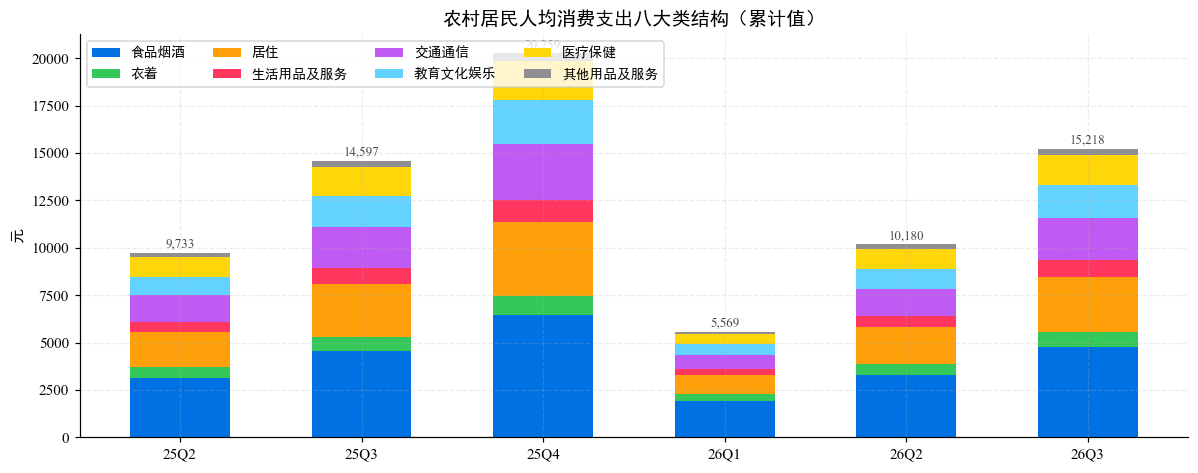

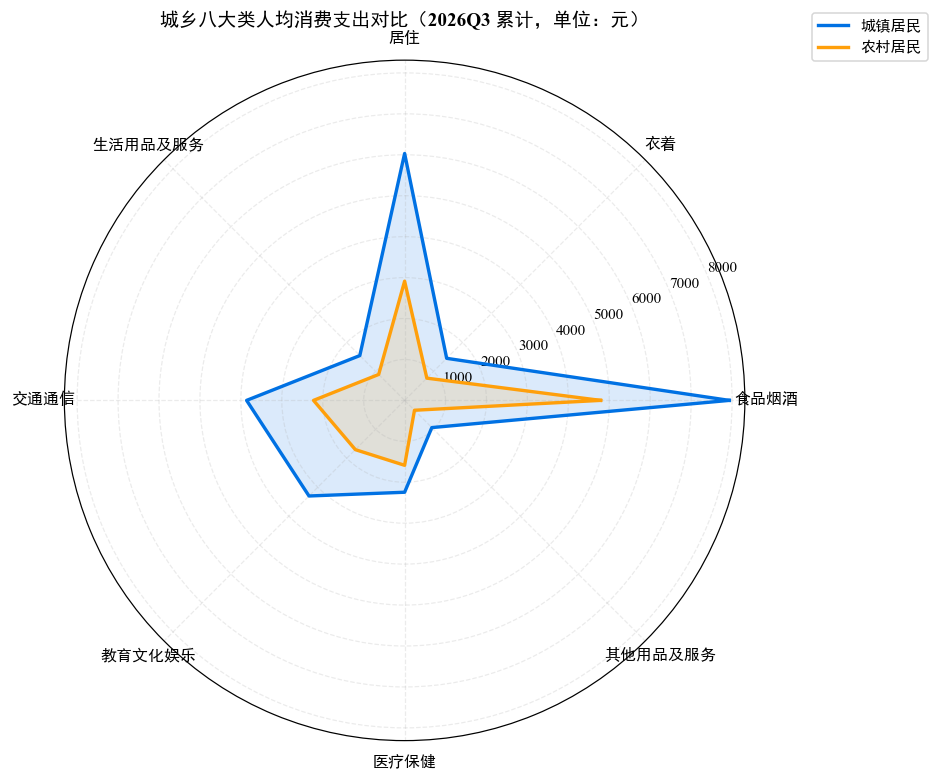

In [7]:
# 表 6：农村居民人均支出情况（与城镇雷达对比）
q_r, rows_r = load_table('农村居民人均支出情况.csv')
q_u, rows_u = load_table('城镇居民人均支出情况.csv')
x = np.arange(len(q_r))
labels = [short_q(q) for q in q_r]

rural_cats = np.array([col(rows_r, f'农村居民人均{c}支出累计值') for c in EXP_CATS])

# 图 1：农村八大类消费支出堆积柱状图
exp_total = col(rows_r, '农村居民人均消费支出累计值')
fig, ax = plt.subplots(figsize=(11, 4.4))
bottom = np.zeros(len(q_r))
for i, (c, vals) in enumerate(zip(EXP_CATS, rural_cats)):
    ax.bar(x, vals, 0.55, bottom=bottom, label=c, color=PAL[i])
    bottom += vals
for xi, tv in enumerate(exp_total):
    ax.text(xi, bottom[xi] + 250, f'{tv:,.0f}', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels)
ax.set_ylabel('元')
ax.set_title('农村居民人均消费支出八大类结构（累计值）')
ax.legend(ncol=4, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：城乡八大类支出雷达图（最新季度）
latest = len(q_r) - 1
urban_cats = [col(rows_u, f'城镇居民人均{c}支出累计值')[latest] for c in EXP_CATS]
rural_v = rural_cats[:, latest].tolist()
angles = np.linspace(0, 2 * np.pi, len(EXP_CATS), endpoint=False).tolist()
angles += angles[:1]
urban_closed = urban_cats + urban_cats[:1]
rural_closed = rural_v + rural_v[:1]
fig = plt.figure(figsize=(8.2, 7.2))
ax = fig.add_subplot(111, polar=True)
ax.plot(angles, urban_closed, color=PAL[0], lw=2.2, label='城镇居民')
ax.fill(angles, urban_closed, color=PAL[0], alpha=0.14)
ax.plot(angles, rural_closed, color=PAL[2], lw=2.2, label='农村居民')
ax.fill(angles, rural_closed, color=PAL[2], alpha=0.14)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(EXP_CATS, fontsize=10.5)
ax.set_title(f'城乡八大类人均消费支出对比（{q_r[latest]} 累计，单位：元）', pad=22)
ax.legend(loc='upper right', bbox_to_anchor=(1.28, 1.08), fontsize=10)
plt.tight_layout()
plt.show()

## 表 7 · 外出务工情况

**图 1** 双轴组合图：外出务工农村劳动力（柱，万人）与月均收入（线，元）。
注：该表为**单季度**数据（非累计），2025Q4 单季数据统计局未发布，故横轴不连续。

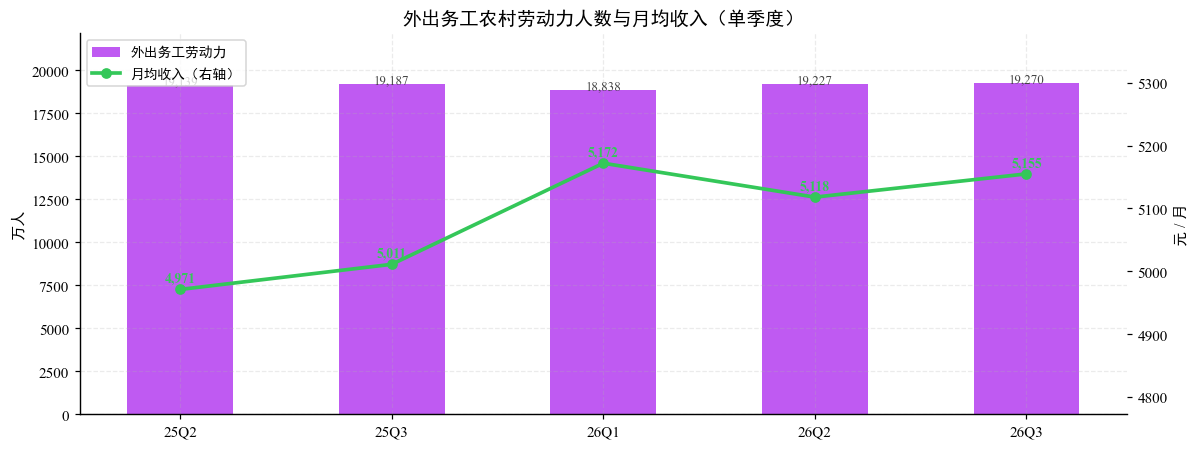

In [8]:
# 表 7：外出务工情况（单季度数据）
quarters, rows = load_table('外出务工情况.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

workers = col(rows, '农村外出务工劳动力')
wage = col(rows, '外出务工农村劳动力月均收入')

fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.bar(x, workers, 0.5, label='外出务工劳动力', color=PAL[4])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 12,
            f'{b.get_height():,.0f}', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels)
ax.set_ylabel('万人')
ax.set_ylim(0, max(workers) * 1.15)
ax2 = ax.twinx()
ax2.plot(x, wage, 'o-', color=PAL[1], lw=2.4, label='月均收入（右轴）')
for xi, yi in zip(x, wage):
    ax2.text(xi, yi + 12, f'{yi:,.0f}', ha='center', fontsize=9, color=PAL[1], fontweight='bold')
ax2.set_ylabel('元 / 月')
ax2.set_ylim(min(wage) * 0.96, max(wage) * 1.04)
ax2.grid(False)
ax.set_title('外出务工农村劳动力人数与月均收入（单季度）')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()